# 从零实现 Logistic Regression: 学生期末考试通过预测

这是一份你已完成实现、根据[错题本](01_student_pass_mistakes.md)修订的学习笔记。
保留数据生成、公式、函数签名、输入输出约定和原有算法思路，修正错题本记录的问题。
11 个函数均已实现；数据检查、自检和画图是辅助代码。

## 使用方法

1. 在 VS Code / Jupyter 中选择本目录 `C1_W3/.venv/bin/python` 对应的 kernel。
2. 保存文件后从上往下运行，核对每个函数及紧随其后的自检。
3. 修改函数后重新运行定义它的单元格；编辑器里的新代码不会自动更新 kernel。
4. 每完成一项，保留函数名、参数顺序及返回值约定，让后续调用可以直接衔接。
5. 使用 Restart Kernel → Run All 验证训练与评估，排除旧变量掩盖错误的情况。

核心限制：仅用 NumPy 手写前向传播、BCE、反向传播和梯度下降，不调用 sklearn 的分类器、
自动求导或现成优化器。不得把模拟数据生成器的系数、`z` 或 `prob` 交给训练函数。

## 路线

问题与形状 → 数据生成与拆分 → 特征标准化 → 参数初始化 → Sigmoid → Forward →
BCE → Backward → Update → 训练循环 → 分类与测试评估 → 学习记录。

## 与英文课程 notebook 的对应关系

[C1_W3_Logistic_Regression.ipynb](C1_W3_Logistic_Regression.ipynb) 是同一主题的课程练习，**不是本题的逐句英文翻译**。
其第 2 节预测大学录取（两个考试分数）；本题预测期末考试通过（三个学习特征）。
下表对应的是**无正则化**的共同算法，输入与参数相同时才应比较数值结果。

| 本题练习 / 函数 | 英文课程位置 / 函数 | 对照时要注意 |
| --- | --- | --- |
| A: `fit_standardizer` / `transform_features` | 第 2 节没有对应预处理函数 | 本题只拟合训练集统计量，英文课程直接使用原始考试分数 |
| B: `initialize_parameters` | 第 2.6 节训练前的 `initial_w` / `initial_b` | 本题零初始化；英文训练示例随机初始化权重、偏置为 -8 |
| C: `sigmoid` | 第 2.3 节 / Exercise 1: `sigmoid` | 同一逐元素公式 |
| D: `forward_pass(X, W, b)` | `compute_cost` / `compute_gradient` / `predict` 内的 `z_wb`、`f_wb` | 本题抽成独立函数并向量化 |
| E: `binary_cross_entropy(y, y_hat)` | 第 2.4 节 / Exercise 2: `compute_cost(X, y, w, b)` | 英文函数内部先前向传播；本题接收概率，并裁剪概率以防 `log(0)` |
| F: `backward_pass(X, y, y_hat)` | 第 2.5 节 / Exercise 3: `compute_gradient(X, y, w, b)` | 本题返回 `(dW, db)`；英文返回 `(dj_db, dj_dw)`，顺序相反 |
| G: `update_parameters` | 第 2.6 节 `gradient_descent` 中的更新语句 | 同样沿负梯度更新，不再除以样本数 |
| H: `train_logistic_regression` | 第 2.6 节 `gradient_descent` | 英文调用须设置 `lambda_=0` 并使用相同初始参数、输入、学习率、迭代次数 |
| I: `predict(y_hat)` | 第 2.8 节 / Exercise 4: `predict(X, w, b)` | 本题只做阈值比较；英文还包括前向传播；两者均使用 `>= 0.5` |
| I: `accuracy_score(y, y_pred)` | `np.mean(p == y_train)` | 本题返回比例；英文显示时乘 100 |

形状转换：本题 `W: (d, 1)`、`y: (m, 1)`；英文 `w: (d,)`、`y: (m,)`，其中英文的 `n` 就是本题的 `d`。
对照时使用 `W.reshape(-1)`、`y.reshape(-1)`，英文梯度/预测再用 `.reshape(-1, 1)` 转回来，
不要把一维标签与列向量直接相减或比较。

损失记录时机也不同：本题 `loss_history[t]` 记录第 `t+1` 次更新**之前**的损失，
英文 `J_history[t]` 记录该次更新**之后**的损失。因此应比较最终参数及重新计算的最终损失；
对相同训练过程，`loss_history[1:]` 才对应 `J_history[:-1]`（少于 100,000 次迭代时）。
英文原实现没有概率裁剪，所以损失数值对照使用远离 0/1 的概率；端点稳定性以本题自检为准。

**范围差异**：英文第 3 节另外包含微芯片数据、六次多项式特征映射和 L2 正则化，本题尚未覆盖。
本题的训练/测试划分、测试评估、多数类基线也不在英文第 2 节的训练集评估中。
英文课程依赖 `utils.py`、`public_tests.py`、`data/` 和 `images/`，当前目录缺少这些课程资源；
其已有输出不能作为当前环境重新运行成功的证据。本题的数据与函数自包含，可以独立运行。

数值对照复核：在 `(m, d) = (2, 1), (3, 2), (7, 3), (11, 5)` 的共同输入上，
前向、BCE、梯度、更新、预测、准确率、最终参数及错位对齐后的损失历史均在绝对容差 `1e-12` 内与英文函数一致。
这是对 notebook 中函数定义的独立检查，不代表英文课程的缺失资源或完整运行已修复。


## 1. Problem Definition

某大学希望根据学生的学习记录，估计学生通过期末考试的概率。

| 字段 | 含义 | 原始范围 | 在模型中的位置 |
| --- | --- | --- | --- |
| Study Hours | 每天学习时间 | 0–10 小时 | $x_1$ |
| Attendance | 课堂出勤率 | 50%–100%，代码存为 0.5–1.0 | $x_2$ |
| Practice Score | 平时练习成绩 | 0–100 | $x_3$ |
| Label | 是否通过期末考试 | 0 或 1 | $y$，不是输入特征 |

目标是学习条件概率：

$$P(\mathrm{Pass}=1\mid x_1,x_2,x_3)$$

Logistic Regression 模型为：

$$z=w_1x_1+w_2x_2+w_3x_3+b,\qquad
\hat y=\sigma(z)=\frac{1}{1+e^{-z}}$$

`y_hat` 是通过概率，不是 0/1 分类结果。最终评估时才使用阈值进行分类。

| 数据划分 | 样本数 | 用途 |
| --- | ---: | --- |
| 总数据 | 2,000 | 模拟学生记录 |
| Training Set | 1,600 | 计算标准化统计量、训练参数 |
| Test Set | 400 | 最后评估，不参与参数更新 |

这里的标签由 Bernoulli 抽样产生。例如，通过概率为 0.8 的学生仍可能得到标签 0。
所以即使学习到了正确规律，也不意味着测试准确率达到 100%。

## 2. 环境与本练习用到的 API

模型只依赖 NumPy；Matplotlib 仅用于最后画训练曲线。
本 notebook 不依赖课程包中的 `utils.py`、`lab_utils_common` 或额外数据文件。

以下为本练习需要的**简化调用形式**，并非 API 的全部参数。点击 API 名称即可查看官方文档。

| API / 语法（官方文档） | 参数与结果 | 在本练习中的用途 |
| --- | --- | --- |
| [`np.random.default_rng(seed)`](https://numpy.org/doc/stable/reference/random/generator.html#numpy.random.default_rng) | 固定种子的随机数生成器 | 复现数据生成步骤 |
| [`rng.uniform(low, high, size)`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.uniform.html) | 在给定区间采样；size 决定形状 | 生成特征 |
| [`rng.binomial(n, p, size=None)`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.binomial.html) | 二项分布采样；n=1 时是 Bernoulli | 根据概率生成 0/1 标签 |
| [`rng.permutation(n)`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.permutation.html) | 返回 0 到 n-1 的随机排列 | 拆分训练集与测试集 |
| [`np.column_stack(arrays)`](https://numpy.org/doc/stable/reference/generated/numpy.column_stack.html) | 把一维数组按列拼接 | 生成三列特征矩阵 |
| [`a.reshape(-1, 1)`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.reshape.html) | 自动推断行数，保留一列 | 让标签成为列向量 |
| [`a.shape / a.shape[0]`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.shape.html) | 形状元组 / 第一维长度 | 检查样本数与维度 |
| [`np.zeros(shape, dtype=float)`](https://numpy.org/doc/stable/reference/generated/numpy.zeros.html) | 指定形状的浮点零数组 | 初始化权重 |
| [`np.mean(a, axis=None, keepdims=False)`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) | 按轴求平均；没有 ddof 参数 | 列均值、损失、偏置梯度 |
| [`np.std(a, axis=None, ddof=0, keepdims=False)`](https://numpy.org/doc/stable/reference/generated/numpy.std.html) | 标准差；分母是 N - ddof，本题用 0 | 特征缩放 |
| [`np.exp(a)`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html) | 逐元素求 $e^a$，保持数组形状 | Sigmoid |
| [`np.log(a)`](https://numpy.org/doc/stable/reference/generated/numpy.log.html) | 逐元素求自然对数 | BCE |
| [`np.clip(a, lower, upper)`](https://numpy.org/doc/stable/reference/generated/numpy.clip.html) | 简写的三个位置参数；不传 out 时返回结果数组 | 裁剪概率数组，避免 log(0) |
| [`A @ B`](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html) | 矩阵乘法，二维时对共享维度求和 | 线性层、权重梯度 |
| [`A.T`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.T.html) | 二维数组转置 | 构造 (d, m) 的特征转置 |
| [`a * b`](https://numpy.org/doc/stable/reference/generated/numpy.multiply.html) | 逐元素乘法，允许广播 | 逐样本损失项 |
| [`a.astype(int)`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html) | 转成整数数组 | 把阈值比较结果转为 0/1 |
| [`np.isfinite(a)`](https://numpy.org/doc/stable/reference/generated/numpy.isfinite.html) | 逐元素判断是否有限 | 检查 NaN、Inf |
| [`np.all(condition)`](https://numpy.org/doc/stable/reference/generated/numpy.all.html) | 所有条件是否成立 | 汇总自检条件 |
| [`np.testing.assert_allclose(actual, desired, atol=...)`](https://numpy.org/doc/stable/reference/generated/numpy.testing.assert_allclose.html) | 在浮点容差内比较 | 检查函数结果 |
| [`np.testing.assert_array_equal(actual, desired)`](https://numpy.org/doc/stable/reference/generated/numpy.testing.assert_array_equal.html) | 严格比较数组元素 | 检查标签与输入未修改 |

`axis=0` 表示跨样本汇总，每个特征得到一个数。对二维数组使用 `keepdims=True`，结果保持 `(1, d)`。
`np.mean` 不接受 `ddof`，`np.std` 接受；损失与偏置梯度对全部样本求平均，返回 `float`。
`@` 和 `*` 含义不同；`X.T @ diff / m` 等于 `(X.T @ diff) / m`。

形状与语法：[`boolean indexing`](https://numpy.org/doc/stable/user/basics.indexing.html#boolean-array-indexing)、[`broadcasting`](https://numpy.org/doc/stable/user/basics.broadcasting.html)、[`operator precedence`](https://docs.python.org/3.13/reference/expressions.html#operator-precedence)。

### 辅助代码 API 索引

| 用途 | 官方文档 |
| --- | --- |
| 构造/复制数组、迭代轴 | [`np.array`](https://numpy.org/doc/stable/reference/generated/numpy.array.html)、[`ndarray.copy`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.copy.html)、[`np.arange`](https://numpy.org/doc/stable/reference/generated/numpy.arange.html) |
| 数据划分检查 | [`np.unique`](https://numpy.org/doc/stable/reference/generated/numpy.unique.html)、[`np.intersect1d`](https://numpy.org/doc/stable/reference/generated/numpy.intersect1d.html)、[`np.concatenate`](https://numpy.org/doc/stable/reference/generated/numpy.concatenate.html) |
| 标签与数据类型检查 | [`np.full`](https://numpy.org/doc/stable/reference/generated/numpy.full.html)、[`np.issubdtype`](https://numpy.org/doc/stable/reference/generated/numpy.issubdtype.html) |
| 训练循环与记录 | [`range`](https://docs.python.org/3.13/library/stdtypes.html#range)、[`list.append`](https://docs.python.org/3.13/tutorial/datastructures.html#more-on-lists)、[`max`](https://docs.python.org/3.13/library/functions.html#max) |
| 标量转换与辅助检查 | [`float`](https://docs.python.org/3.13/library/functions.html#float)、[`int`](https://docs.python.org/3.13/library/functions.html#int)、[`len`](https://docs.python.org/3.13/library/functions.html#len)、[`isinstance`](https://docs.python.org/3.13/library/functions.html#isinstance)、[`print`](https://docs.python.org/3.13/library/functions.html#print)、[`set`](https://docs.python.org/3.13/library/stdtypes.html#set-types-set-frozenset)、[`set.issubset`](https://docs.python.org/3.13/library/stdtypes.html#frozenset.issubset)、[`ValueError`](https://docs.python.org/3.13/library/exceptions.html#ValueError) |
| 创建/显示图形 | [`plt.subplots`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)、[`plt.show`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.show.html) |
| 曲线、坐标与布局 | [`ax.plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html)、[`ax.set_xlabel`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xlabel.html)、[`ax.set_ylabel`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_ylabel.html)、[`ax.set_title`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_title.html)、[`ax.grid`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.grid.html)、[`fig.tight_layout`](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.tight_layout.html) |

`fit_standardizer` 到 `accuracy_score` 是本 notebook 自定义函数，接口以各自 docstring 为准，没有第三方官方 API 页面。


In [1]:
import numpy as np

print("NumPy version:", np.__version__)

NumPy version: 2.5.4


## 3. Generate Dataset — 题目已给定

下面的数据生成逻辑、随机种子和调用顺序保持题目设定。
原题片段缺少测试标签，因此补充了 `y_test = y[test_idx]`。

阅读提示：

- `hours`、`attendance`、`practice` 各有 2,000 个值。
- `X` 的每一行是一个学生，每一列是一个特征。
- `z` 和 `prob` 属于**数据生成器**，不是训练时已知的答案。
- `rng.binomial(1, prob)` 产生概率标签，不能改成对 `prob` 直接做阈值判断。
- 不要在本单元格中途插入随机调用，否则后面的随机结果也会改变。
- 从头重跑本单元格会重建随机数生成器；调试时请保持数据拆分固定。

In [2]:
# 已提供的数据准备，不是待实现的训练算法。
rng = np.random.default_rng(42)
N = 2000

# 三列特征；attendance 用小数表示，例如 0.9 表示 90%。
hours = rng.uniform(0, 10, N)
attendance = rng.uniform(0.5, 1.0, N)
practice = rng.uniform(0, 100, N)
X = np.column_stack([hours, attendance, practice])

# 仅用于模拟真实规律。训练函数不得读取这里的系数、z 或 prob。
z = (
    -1.5
    + 0.35 * hours
    + 4.0 * (attendance - 0.75)
    + 0.025 * (practice - 50)
)
prob = 1 / (1 + np.exp(-z))
y = rng.binomial(1, prob).reshape(-1, 1)

# 同一组索引同时切分 X 和 y，确保特征与标签一一对应。
indices = rng.permutation(N)
train_idx = indices[:1600]
test_idx = indices[1600:]

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]  # 补齐原题省略的测试标签，仅在最后评估时使用。

In [3]:
# 数据准备自检：这里不训练模型，也不估计标准化参数。
assert X.shape == (2000, 3)
assert y.shape == (2000, 1)
assert X_train.shape == (1600, 3)
assert y_train.shape == (1600, 1)
assert X_test.shape == (400, 3)
assert y_test.shape == (400, 1)
assert set(np.unique(y)).issubset({0, 1})
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.unique(np.concatenate([train_idx, test_idx]))) == N
assert np.all((X[:, 0] >= 0) & (X[:, 0] <= 10))
assert np.all((X[:, 1] >= 0.5) & (X[:, 1] <= 1.0))
assert np.all((X[:, 2] >= 0) & (X[:, 2] <= 100))

print("Data checks passed.")
print("Training shapes:", X_train.shape, y_train.shape)
print("Test shapes:", X_test.shape, y_test.shape)
print("First three training records:\n", X_train[:3])
print("Their labels:\n", y_train[:3])

Data checks passed.
Training shapes: (1600, 3) (1600, 1)
Test shapes: (400, 3) (400, 1)
First three training records:
 [[ 7.93682151  0.78018695 84.94618186]
 [ 5.86445173  0.73185986  2.44834415]
 [ 3.03796618  0.66447183 65.09439234]]
Their labels:
 [[1]
 [1]
 [0]]


## 4. 统一形状约定

后面的函数用通用样本数 $m$ 和特征数 $d$，而不是在内部写死 1,600 或 3。
训练集有 $m=1600$，测试集有 $m=400$，本题 $d=3$。

| 变量 | 通用形状 / 类型 | 含义 |
| --- | --- | --- |
| `X_batch` | `(m, d)` | 当前使用的特征矩阵 |
| `y_batch` | `(m, 1)` | 真实标签 |
| `W` | `(d, 1)` | 每个特征的权重 |
| `b` | `float` | 一个共享偏置 |
| `Z` | `(m, 1)` | 线性得分 |
| `y_hat` | `(m, 1)` | 预测通过概率 |
| `dW` | `(d, 1)` | 损失对权重的梯度 |
| `db` | `float` | 损失对偏置的梯度 |
| `mean`, `scale` | `(1, d)` | 训练集各列均值与安全标准差 |
| `loss` | `float` | 一个批次的平均损失 |

最常见的陷阱：`(m, 1)` 减去 `(m,)` 会广播成 `(m, m)`，不一定立即报错。
因此标签、概率和分类输出都保持列向量。`b` 在加法中自动广播到所有样本。
类型注解 [`np.ndarray`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.html) 不会自动检查这些形状，需要你自己检查。

## 5. 练习 A — 特征标准化

这一节是为训练稳定性增加的预处理，不改变 Logistic Regression 的四个核心步骤。
三个输入量纲不同，练习成绩的数值范围远大于出勤率，直接使用同一学习率可能难以稳定收敛。

只在训练集估计每列的均值 $\mu_j$ 和标准差 $s_j$：

$$\widetilde{x}_{ij}=\frac{x_{ij}-\mu_j}{s_j}$$

本练习约定：使用 `ddof=0`；若某列标准差小于等于 `eps`，把该列的缩放因子设为 1。
这样常数列不会产生除零问题。本题随机数据通常不会出现常数列，自检会覆盖这种情况。

你需要完成两个函数：

1. `fit_standardizer`：只从传入的训练矩阵计算 `mean` 和 `scale`。
2. `transform_features`：使用已经得到的统计量变换任意一批特征，不能重新估计统计量。

测试集必须复用训练集的 `mean` 和 `scale`。不要先对全部 2,000 个样本标准化再拆分。
保留 `X_train`、`X_test` 原始值，将变换结果命名为 `X_train_scaled`、`X_test_scaled`。

API 提示：`np.mean`、`np.std`、`axis=0`、`keepdims=True`、布尔索引。

**错题回顾 A-1–A-3**（[完整记录](01_student_pass_mistakes.md)）：`mean` / `scale` 要接住计算结果；`axis=0, keepdims=True` 保留 `(1, d)`；布尔索引只替换近零项；最后返回两个数组。

官方 API：[`np.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html)、[`np.std`](https://numpy.org/doc/stable/reference/generated/numpy.std.html)、[`boolean indexing`](https://numpy.org/doc/stable/user/basics.indexing.html#boolean-array-indexing)。


In [4]:
def fit_standardizer(
    X_train: np.ndarray,
    eps: float = 1e-12,
) -> tuple[np.ndarray, np.ndarray]:
    """仅用训练数据估计标准化参数。

    Parameters
    ----------
    X_train : ndarray, shape (m, d)
        非空、有限的原始训练特征，至少包含一个样本。
    eps : float
        判断近似零标准差的阈值，必须大于 0。

    Returns
    -------
    mean : ndarray, shape (1, d)
        每一列的训练均值。
    scale : ndarray, shape (1, d)
        每一列的总体标准差；小于等于 eps 的项替换成 1。

    Notes
    -----
    不修改传入的 X_train，不访问全局 X 或 X_test。
    """
    # 步骤 A1: 找到表示“每个特征”的汇总轴，并保留二维形状。

    # 步骤 A2: 计算各列均值、总体标准差。
    mean = np.mean(X_train, axis=0, keepdims=True)
    scale = np.std(X_train, axis=0, ddof=0, keepdims=True)
    # 步骤 A3: 处理近似零标准差，再按约定返回两个数组。
    bool_arr = scale <= eps
    scale[bool_arr] = 1.0
    return mean, scale


def transform_features(
    X: np.ndarray,
    mean: np.ndarray,
    scale: np.ndarray,
) -> np.ndarray:
    """使用训练统计量变换特征，返回新的浮点数组。

    X 的形状为 (m, d)，mean 和 scale 均为 (1, d)。
    返回值 X_scaled 的形状为 (m, d)，不修改任何输入。
    scale 来自 fit_standardizer，因此所有元素均大于 0。
    注意：这里不能重新计算 mean 或 scale，也不接收标签。
    """
    # 步骤 A4: 根据标准化公式，用广播把每列变换到对应尺度。
    X_scaled = (X - mean) / scale
    return X_scaled


In [5]:
# 完成练习 A 后运行；第三列特意设为常数。
A = np.array([[1.0, 10.0, 7.0], [3.0, 14.0, 7.0], [5.0, 18.0, 7.0]])
A_before = A.copy()
mean_a, scale_a = fit_standardizer(A)
assert mean_a.shape == scale_a.shape == (1, 3)
np.testing.assert_allclose(mean_a, [[3.0, 14.0, 7.0]])
assert np.all(scale_a > 0)
np.testing.assert_allclose(scale_a[0, 2], 1.0)

A_scaled = transform_features(A, mean_a, scale_a)
assert A_scaled.shape == A.shape
np.testing.assert_allclose(np.mean(A_scaled, axis=0), [0, 0, 0], atol=1e-12)
np.testing.assert_allclose(np.std(A_scaled[:, :2], axis=0), [1, 1], atol=1e-12)
np.testing.assert_allclose(A_scaled[:, 2], 0.0, atol=1e-12)
np.testing.assert_array_equal(A, A_before)

# 新数据复用相同训练统计量，不会被强行变换为均值 0。
unseen = np.array([[7.0, 22.0, 7.0]])
unseen_scaled = transform_features(unseen, mean_a, scale_a)
assert unseen_scaled.shape == (1, 3)
assert np.all(unseen_scaled[0, :2] > 0)

# 近似零标准差也使用 1.0 作为缩放因子，而不是 eps。
_, scale_near_zero = fit_standardizer(np.array([[0.0], [1e-14]]))
np.testing.assert_array_equal(scale_near_zero, [[1.0]])
print("Exercise A checks passed.")


Exercise A checks passed.


## 6. 练习 B — 初始化参数

本题把 `W` 初始化为全零浮点列向量，把 `b` 初始化为 `0.0`。
单层 Logistic Regression 可以使用零初始化；不需要从生成数据的公式中读取任何系数。
`n_features` 必须由调用者提供，函数内部不要写死为 3。

API 提示：`np.zeros(shape, dtype=float)` 中的 `shape` 是元组；`(d,)` 和 `(d, 1)` 不同。

**错题回顾 B-1**（[完整记录](01_student_pass_mistakes.md)）：只读形参 `n_features`，不能读取全局 `d`。本节自检改用局部变量，并覆盖 1、3、5 列。

官方 API：[`np.zeros`](https://numpy.org/doc/stable/reference/generated/numpy.zeros.html)。


In [6]:
def initialize_parameters(n_features: int) -> tuple[np.ndarray, float]:
    """初始化模型参数。

    n_features : 正整数，特征数 d。
    返回 W : 浮点数组，shape (d, 1)，所有元素为 0。
    返回 b : Python float，初始值为 0.0。
    """
    # 步骤 B1: 按约定创建参数，并以 (W, b) 的顺序返回。
    W = np.zeros((n_features, 1), dtype=float)
    b = 0.
    return (W, b)


In [7]:
# 在局部作用域内检查多个维度，不用全局 d 给错误实现“兜底”。
def check_initialization():
    for expected_features in (1, 3, 5):
        W_check, b_check = initialize_parameters(expected_features)
        assert W_check.shape == (expected_features, 1)
        assert np.issubdtype(W_check.dtype, np.floating)
        np.testing.assert_array_equal(W_check, np.zeros((expected_features, 1)))
        assert isinstance(b_check, float) and b_check == 0.0


check_initialization()
print("Exercise B checks passed.")


Exercise B checks passed.


## 7. 练习 C — Sigmoid

$$\sigma(z)=\frac{1}{1+e^{-z}}$$

请实现逐元素的向量化计算，输入和输出的形状相同，不要逐个学生写 Python 循环。
数学上概率属于 $(0,1)$；浮点数运算中极端输入可能得到数值上的 0 或 1。

先完成正常输入范围，再思考数值稳定性：当 $z$ 非常负时，指数函数可能溢出。
可以研究如何按输入正负分开计算等价表达式；本节基础自检不要求先完成极端值扩展。
不要为了实现激活函数而复制数据生成部分的现成代码。

API 提示：`np.exp` 可以直接处理整个数组；普通 [`math.exp`](https://docs.python.org/3.13/library/math.html#math.exp) 不适合本题的数组输入。

**错题回顾 C-1**（[完整记录](01_student_pass_mistakes.md)）：必须包含完整的 `1 / (1 + exp(-Z))`；用 σ(0)=0.5 检查漏项。极端负数的稳定性仍是可选扩展。

官方 API：[`np.exp`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html)。


In [8]:
def sigmoid(Z: np.ndarray) -> np.ndarray:
    """将线性得分转换为概率。

    Z : 有限的浮点数组，常用 shape (m, 1)。
    返回值 : 与 Z 形状相同的浮点数组，数值落在 [0, 1]。
    不修改 Z；函数应能处理其他数组形状，便于独立验证。
    """
    # 步骤 C1: 将 Sigmoid 公式翻译成 NumPy 的逐元素运算。
    ans = 1 / (np.exp(-Z) + 1)
    # 可选扩展 C2: 支持极端输入，避免指数计算溢出。
    return ans


In [9]:
Z_check = np.array([[-2.0], [0.0], [2.0]])
S_check = sigmoid(Z_check)
assert S_check.shape == Z_check.shape
np.testing.assert_allclose(S_check[1, 0], 0.5, atol=1e-12)
np.testing.assert_allclose(S_check[0, 0] + S_check[2, 0], 1.0, atol=1e-12)
assert S_check[0, 0] < S_check[1, 0] < S_check[2, 0]
assert np.all(np.isfinite(S_check))
assert np.all((S_check >= 0) & (S_check <= 1))
assert sigmoid(np.zeros((2, 3))).shape == (2, 3)
print("Exercise C checks passed.")

Exercise C checks passed.


## 8. 练习 D — Step 1: Forward Pass

$$Z=XW+b,\qquad \hat Y=\sigma(Z)$$

形状推理：`(m, d) @ (d, 1)` 得到 `(m, 1)`；加上标量 `b` 后形状不变。
接着调用自己实现的 `sigmoid`，得到每个学生的通过概率。

本练习约定 `forward_pass` 只返回概率数组。`Z` 是函数内部的中间变量。
这里不要使用 0.5 阈值，也不要计算损失或更新参数。

**错题回顾 D-1**（[完整记录](01_student_pass_mistakes.md)）：使用 `@` 汇总特征乘积；`*` 只逐元素相乘。新增 m≠d 的样例，避免方阵掩盖形状错误。

官方 API：[`np.matmul`](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html)、[`np.multiply`](https://numpy.org/doc/stable/reference/generated/numpy.multiply.html)、[`broadcasting`](https://numpy.org/doc/stable/user/basics.broadcasting.html)。


In [10]:
def forward_pass(X: np.ndarray, W: np.ndarray, b: float) -> np.ndarray:
    """计算一批样本的预测通过概率。

    X : shape (m, d)，训练时通常已经标准化。
    W : shape (d, 1)，当前权重。
    b : float，当前偏置。
    返回 y_hat : shape (m, 1)，不是分类标签。
    不访问全局训练集，不修改 X、W 或 b。
    """
    # 步骤 D1: 先计算线性得分，确认矩阵乘法方向。
    Z = X @ W + b

    # 步骤 D2: 调用自己的 sigmoid 并返回概率。
    Y_hat = sigmoid(Z)
    return Y_hat


In [11]:
X_check = np.array([[1.0, 2.0], [3.0, 4.0]])
W_zero = np.zeros((2, 1))
p_zero = forward_pass(X_check, W_zero, 0.0)
assert p_zero.shape == (2, 1)
np.testing.assert_allclose(p_zero, 0.5, atol=1e-12)

# 权重为 0 时，改变偏置应对所有样本产生同样影响。
p_bias = forward_pass(X_check, W_zero, 1.0)
assert p_bias.shape == (2, 1)
assert np.all(p_bias > 0.5)
np.testing.assert_allclose(p_bias[0], p_bias[1])

# 非零权重样例：两行的线性得分可用纸笔算出，检查特征顺序。
p_weighted = forward_pass(X_check, np.array([[1.0], [-1.0]]), 0.0)
np.testing.assert_allclose(p_weighted, [[0.26894142137], [0.26894142137]], atol=1e-10)

# m != d：逐元素乘法不能冒充矩阵乘法。
X_rect = np.array([[1.0, 2.0], [3.0, 4.0], [-1.0, 1.0]])
p_rect = forward_pass(X_rect, np.array([[1.0], [-1.0]]), 0.5)
assert p_rect.shape == (3, 1)
np.testing.assert_allclose(p_rect, sigmoid(np.array([[-0.5], [-0.5], [-1.5]])))
print("Exercise D checks passed.")


Exercise D checks passed.


## 9. 练习 E — Step 2: Binary Cross Entropy

$$L=-\frac{1}{m}\sum_{i=1}^{m}\left[
y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)\right]$$

先计算每个样本的损失，再对样本求平均，最终返回一个 Python `float`。
这里的 `log` 是自然对数，不能用 `log10`。

为避免浮点运算中的 `log(0)`，本练习约定在函数内部将概率副本限制在
`[eps, 1-eps]`，默认 `eps=1e-12`。不要原地修改传入的 `y_hat`。
反向传播使用原始 Sigmoid 概率，裁剪仅用于让损失数值有限。

思考：当所有预测都是 0.5 时，损失应为 $\log 2\approx0.693147$，与标签比例无关。
把真实标签直接当预测概率传入，不能用于判断模型是否学会了任务。

API 提示：`np.clip`、`np.log`、`np.mean`、`float`。

**错题回顾 E-1–E-5**（[完整记录](01_student_pass_mistakes.md)）：裁剪对象是 `y_hat`；`np.mean` 没有 `ddof`；BCE 返回单个 `float`，不保留 `(1, 1)` 维度。

官方 API：[`np.clip`](https://numpy.org/doc/stable/reference/generated/numpy.clip.html)、[`np.log`](https://numpy.org/doc/stable/reference/generated/numpy.log.html)、[`np.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html)、[`float`](https://docs.python.org/3.13/library/functions.html#float)。


In [12]:
def binary_cross_entropy(
    y_true: np.ndarray,
    y_hat: np.ndarray,
    eps: float = 1e-12,
) -> float:
    """计算平均二元交叉熵。

    y_true : shape (m, 1)，只包含 0/1。
    y_hat : shape (m, 1)，概率；须与 y_true 完全同形。
    eps : 满足 0 < eps < 0.5 的裁剪常数。
    返回 loss : Python float，全部样本的平均损失。
    不修改输入；不返回逐样本数组，也不把概率先转成分类标签。
    """
    # 步骤 E1: 为对数计算准备安全概率，不改变原始 y_hat。
    y_hat_safe = np.clip(y_hat, eps, 1-eps)
    # 步骤 E2: 根据公式构造正类项和负类项。

    # 步骤 E3: 对样本取平均，检查负号与返回类型。
    return float(-np.mean(y_true * np.log(y_hat_safe) + (1 - y_true) * np.log(1 - y_hat_safe)))


In [13]:
y_check = np.array([[0], [1]])
neutral_loss = binary_cross_entropy(y_check, np.array([[0.5], [0.5]]))
assert isinstance(neutral_loss, float)
np.testing.assert_allclose(neutral_loss, 0.69314718056, atol=1e-10)

good_loss = binary_cross_entropy(y_check, np.array([[0.1], [0.9]]))
bad_loss = binary_cross_entropy(y_check, np.array([[0.9], [0.1]]))
assert 0.0 <= good_loss < neutral_loss < bad_loss

# 预测恰好为 0/1 时仍应返回有限损失，且不能修改输入。
edge_prob = np.array([[1.0], [0.0]])
edge_before = edge_prob.copy()
assert np.isfinite(binary_cross_entropy(y_check, edge_prob))
np.testing.assert_array_equal(edge_prob, edge_before)
print("Exercise E checks passed.")

Exercise E checks passed.


## 10. 练习 F — Step 3: Backward Pass

$$dW=\frac{1}{m}X^T(\hat Y-Y),\qquad
db=\frac{1}{m}\sum_{i=1}^{m}(\hat y_i-y_i)$$

`y_hat - y_true` 是每个样本的预测误差，形状应为 `(m, 1)`。
`X.T` 的形状是 `(d, m)`，因此权重梯度最终是 `(d, 1)`。
对偏置的梯度汇总所有样本，返回一个标量。

为什么这里没有额外的 Sigmoid 导数？
对于单个样本，BCE 对概率的导数与 Sigmoid 对线性得分的导数相乘后会化简为
$\partial\ell_i/\partial z_i=\hat y_i-y_i$，再结合线性层即可得到题目公式。
不要在这个结果上再乘一次 $\hat y_i(1-\hat y_i)$。

本函数只计算梯度，不更新参数。分母来自传入矩阵的样本数，不要写死 1,600。
API 提示：`.shape[0]`、`.T`、`@`、`np.mean` 或 [`np.sum`](https://numpy.org/doc/stable/reference/generated/numpy.sum.html)。

**错题回顾 F-1**（[完整记录](01_student_pass_mistakes.md)）：`X.T @ diff` 已对样本求和，只再除以 m；不能把 d 个特征的梯度取 mean 变成一个数。

官方 API：[`ndarray.T`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.T.html)、[`np.matmul`](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html)、[`np.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html)、[`operator precedence`](https://docs.python.org/3.13/reference/expressions.html#operator-precedence)。


In [14]:
def backward_pass(
    X: np.ndarray,
    y_true: np.ndarray,
    y_hat: np.ndarray,
) -> tuple[np.ndarray, float]:
    """用题目中的解析公式计算当前梯度。

    X : shape (m, d)，与前向传播使用的特征完全相同。
    y_true, y_hat : shape (m, 1)，分别为标签和未裁剪的预测概率。
    返回 dW : shape (d, 1)，平均损失对 W 的梯度。
    返回 db : Python float，平均损失对 b 的梯度。
    不修改输入，不访问全局标签，不在这里更新参数。
    """
    # 步骤 F1: 获取当前样本数，并计算预测误差列向量。
    m = X.shape[0]
    diff = y_hat - y_true
    # 步骤 F2: 依据形状推理构造 dW，注意平均只做一次。
    dw = X.T @ diff / m
    db = float(np.mean(diff))
    # 步骤 F3: 汇总偏置梯度，按 (dW, db) 的顺序返回。
    return (dw, db)


In [15]:
# 小样本的期望梯度可手算；不使用真实数据生成器的系数。
X_grad = np.array([[1.0, 2.0], [3.0, 4.0]])
y_grad = np.array([[0], [1]])
p_grad = np.array([[0.5], [0.5]])
dW_check, db_check = backward_pass(X_grad, y_grad, p_grad)
assert dW_check.shape == (2, 1)
assert isinstance(db_check, float)
np.testing.assert_allclose(dW_check, [[-0.5], [-0.5]], atol=1e-12)
np.testing.assert_allclose(db_check, 0.0, atol=1e-12)

# 一个未平衡样例，避免错误的 db 恰巧等于 0 也通过检查。
dW_one, db_one = backward_pass(
    np.array([[2.0, -1.0]]), np.array([[1]]), np.array([[0.25]])
)
np.testing.assert_allclose(dW_one, [[-1.5], [0.75]], atol=1e-12)
np.testing.assert_allclose(db_one, -0.75, atol=1e-12)

# 若人为给定预测概率恰好等于标签，解析误差梯度应为 0。
dW_exact, db_exact = backward_pass(X_grad, y_grad, y_grad.astype(float))
np.testing.assert_allclose(dW_exact, 0.0, atol=1e-12)
np.testing.assert_allclose(db_exact, 0.0, atol=1e-12)
print("Exercise F checks passed.")


Exercise F checks passed.


## 11. 练习 G — Step 4: Update Parameters

$$W_{\mathrm{new}}=W-\alpha dW,\qquad
b_{\mathrm{new}}=b-\alpha db$$

学习率 $\alpha>0$ 控制每次沿负梯度方向移动的步幅。
不要把减法误写成加法，也不要在这里再次除以样本数，因为梯度已经平均过。

本练习约定返回新参数，不原地修改输入的权重，方便调试与比较更新前后的结果。
这里不需要额外的 NumPy 函数，普通数组与标量运算即可。

In [16]:
def update_parameters(
    W: np.ndarray,
    b: float,
    dW: np.ndarray,
    db: float,
    learning_rate: float,
) -> tuple[np.ndarray, float]:
    """执行一次梯度下降更新，返回 (W_new, b_new)。

    W, dW : shape (d, 1)。
    b, db : float。
    learning_rate : 正浮点数。
    W_new 与 W 同形，b_new 为 Python float。
    不原地修改 W，也不在这里重新计算梯度。
    """
    # 步骤 G1: 根据更新公式分别构造新权重与新偏置。
    W_new = W - learning_rate * dW
    b_new = b - learning_rate * db
    # 步骤 G2: 按 (W_new, b_new) 的顺序返回。
    return (W_new, b_new)


In [17]:
W_before = np.array([[1.0], [-2.0]])
W_snapshot = W_before.copy()
W_after, b_after = update_parameters(
    W_before, 0.5, np.array([[0.2], [-0.4]]), -0.1, learning_rate=0.1
)
assert W_after.shape == (2, 1)
assert isinstance(b_after, float)
np.testing.assert_allclose(W_after, [[0.98], [-1.96]], atol=1e-12)
np.testing.assert_allclose(b_after, 0.51, atol=1e-12)
np.testing.assert_array_equal(W_before, W_snapshot)
print("Exercise G checks passed.")

Exercise G checks passed.


## 12. 练习 H — 组装 Full-batch 训练循环

每次迭代使用全部训练样本，按题目的顺序完成：

1. 用当前参数执行前向传播。
2. 计算当前参数对应的 BCE，记录一个损失值。
3. 用同一批概率计算梯度。
4. 更新参数，供下一次迭代使用。

初始化只在进入循环前执行一次，不能每轮把参数重置为零。
训练只使用函数参数 `X_train`、`y_train`，不能使用测试集、全量标签或数据生成器的系数。

**历史记录约定**：`loss_history[t]` 是第 `t+1` 次更新**之前**的训练损失；
列表长度必须等于 `num_iterations`。返回的 `W`、`b` 是全部更新完成后的参数。
因此最终模型的训练损失需要在训练后重新计算，通常不等于 `loss_history[-1]`。

`verbose=True` 时，可以每隔一段迭代打印训练损失，不要逐轮查看测试集表现。
API 提示：`range(num_iterations)`、`list.append(value)`、已经完成的各个函数。

**错题回顾 H-1–H-5**（[完整记录](01_student_pass_mistakes.md)）：按特征数初始化一次；空列表配合 append；把返回值接回 `W`、`b`；循环结束后返回。`verbose=True` 现在按间隔打印更新前损失。

官方 API：[`range`](https://docs.python.org/3.13/library/stdtypes.html#range)、[`list.append`](https://docs.python.org/3.13/tutorial/datastructures.html#more-on-lists)。


In [18]:
def train_logistic_regression(
    X_train: np.ndarray,
    y_train: np.ndarray,
    learning_rate: float = 0.1,
    num_iterations: int = 3000,
    verbose: bool = False,
) -> tuple[np.ndarray, float, list[float]]:
    """使用全批量梯度下降训练 Logistic Regression。

    X_train : shape (m, d)，已用训练集统计量标准化。
    y_train : shape (m, 1)，0/1 标签。
    learning_rate : 正浮点数，不是从数据生成器读取的参数。
    num_iterations : 正整数，参数更新次数。
    verbose : 是否按自选间隔打印训练损失。

    Returns
    -------
    W : shape (d, 1)，最后一次更新后的权重。
    b : float，最后一次更新后的偏置。
    loss_history : list[float]
        每轮更新前的训练 BCE，共 num_iterations 项。

    Notes
    -----
    复用练习 B 到 G 的函数，不在内部另写一套算法。
    不在这里标准化或重新划分数据，不修改传入数组。
    """
    # 步骤 H1: 根据特征数初始化参数，并准备空的损失记录。
    n_features = X_train.shape[1]
    (W, b) = initialize_parameters(n_features)
    loss_history = []
    # 步骤 H2: 组织题目要求的四个训练步骤。
    for i in range(num_iterations):
        y_hat = forward_pass(X_train, W, b)
        # 步骤 H3: 记录本轮更新前损失，按需打印进度。
        loss = binary_cross_entropy(y_true=y_train, y_hat=y_hat)
        loss_history.append(loss)
        if verbose and (i % max(1, num_iterations // 10) == 0 or i == num_iterations - 1):
            print(f"Iteration {i:4d}: BCE before update = {loss:.6f}")
        (dW, db) = backward_pass(X_train, y_true = y_train, y_hat = y_hat)
        (W_new, b_new) = update_parameters(W, b, dW, db, learning_rate = learning_rate)
        W = W_new
        b = b_new
    # 步骤 H4: 返回最后的参数及损失记录。
    return (W, b, loss_history)


In [19]:
# 与正式测试集无关的微型训练自检。
# 两个样本、一列特征，可以检查循环次数、记录时机及是否实际更新。
X_tiny = np.array([[-1.0], [1.0]])
y_tiny = np.array([[0], [1]])

W_once, b_once, history_once = train_logistic_regression(
    X_tiny, y_tiny, learning_rate=0.1, num_iterations=1
)
assert W_once.shape == (1, 1)
assert isinstance(b_once, float)
assert isinstance(history_once, list) and len(history_once) == 1
np.testing.assert_allclose(history_once[0], 0.69314718056, atol=1e-10)
np.testing.assert_allclose(W_once, [[0.05]], atol=1e-12)
np.testing.assert_allclose(b_once, 0.0, atol=1e-12)

W_tiny, b_tiny, history_tiny = train_logistic_regression(
    X_tiny, y_tiny, learning_rate=0.1, num_iterations=50
)
assert len(history_tiny) == 50
assert np.all(np.isfinite(history_tiny))
assert history_tiny[-1] < history_tiny[0]
assert W_tiny[0, 0] > W_once[0, 0]

# verbose=True 确实显示进度；返回参数仍对应一次完整更新。
W_verbose, b_verbose, history_verbose = train_logistic_regression(
    X_tiny, y_tiny, learning_rate=0.1, num_iterations=1, verbose=True
)
np.testing.assert_allclose(W_verbose, W_once)
np.testing.assert_allclose(b_verbose, b_once)
np.testing.assert_allclose(history_verbose, history_once)
print("Exercise H checks passed.")


Iteration    0: BCE before update = 0.693147
Exercise H checks passed.


## 13. 在 1,600 个训练样本上训练

下面调用已经实现的函数。确认前面练习的自检通过后，运行本节。

`learning_rate=0.1`、`num_iterations=3000` 是标准化输入下的起始配置，不保证适合任何数据。
观察训练损失的趋势；若出现 NaN、Inf 或持续上升，先检查形状、梯度符号、平均次数和数值稳定性。
若代码正确，再考虑减小学习率。不要为了挑选超参数反复查看这 400 个测试样本的指标；
需要系统调参时，从训练集另留验证集。

In [20]:
# 这一步只在 X_train 上拟合统计量。
feature_mean, feature_scale = fit_standardizer(X_train)
X_train_scaled = transform_features(X_train, feature_mean, feature_scale)
X_test_scaled = transform_features(X_test, feature_mean, feature_scale)

assert X_train_scaled.shape == X_train.shape
assert X_test_scaled.shape == X_test.shape
np.testing.assert_allclose(
    np.mean(X_train_scaled, axis=0), np.zeros(3), atol=1e-10
)

# 只有训练数据进入训练函数；测试数据不参与更新。
W, b, loss_history = train_logistic_regression(
    X_train_scaled,
    y_train,
    learning_rate=0.1,
    num_iterations=3000,
    verbose=True,
)

assert W.shape == (3, 1)
assert len(loss_history) == 3000
assert np.all(np.isfinite(W)) and np.isfinite(b)
assert np.all(np.isfinite(loss_history))
print("Training finished.")
print("Learned W (standardized feature space):\n", W)
print("Learned b:", b)

Iteration    0: BCE before update = 0.693147
Iteration  300: BCE before update = 0.546423
Iteration  600: BCE before update = 0.546361
Iteration  900: BCE before update = 0.546361
Iteration 1200: BCE before update = 0.546361
Iteration 1500: BCE before update = 0.546361
Iteration 1800: BCE before update = 0.546361
Iteration 2100: BCE before update = 0.546361
Iteration 2400: BCE before update = 0.546361


Iteration 2700: BCE before update = 0.546361


Iteration 2999: BCE before update = 0.546361
Training finished.
Learned W (standardized feature space):
 [[1.00038618]
 [0.59944626]
 [0.6920084 ]]
Learned b: 0.1630350423577999


## 14. 练习 I — 概率转标签与 Accuracy

固定分类阈值为 0.5：

$$\hat y_{\mathrm{class},i}=
\begin{cases}1,&\hat y_i\geq 0.5\\0,&\hat y_i<0.5\end{cases}$$

$$\mathrm{Accuracy}=\frac{\text{预测正确的样本数}}{\text{样本总数}}$$

`predict` 接收概率数组，不能在这里重新训练或重新标准化。
本练习约定**恰好等于阈值时归为 1**，返回整数列向量。
`accuracy_score` 接收真实标签和预测标签，返回 `[0, 1]` 内的比例；格式化为百分比在显示时完成。

API 提示：数组比较生成布尔数组，`astype(int)` 转类型；对布尔数组求平均可以得到正确比例。

**错题回顾 I-1–I-2**（[完整记录](01_student_pass_mistakes.md)）：阈值边界用 `>=`；准确率用相等比较后取平均，并先拒绝形状不一致。

官方 API：[`ndarray.astype`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html)、[`np.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html)。


In [21]:
def predict(y_hat: np.ndarray, threshold: float = 0.5) -> np.ndarray:
    """把概率转换为 0/1 标签。

    y_hat : shape (m, 1)，预测概率。
    threshold : 分类阈值，取值在 (0, 1)，本题固定用 0.5。
    返回 y_pred : shape (m, 1)，整数数组；概率 >= threshold 时为 1。
    不修改 y_hat。
    """
    # 步骤 I1: 用一次向量化比较完成分类，并转换成整数。
    return (y_hat >= threshold).astype(int)


def accuracy_score(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """返回分类正确比例，而不是百分数。

    y_true, y_pred : 完全同形的非空 (m, 1) 0/1 数组。
    返回 accuracy : Python float，范围 [0, 1]。
    先确认两者同形，避免 (m, 1) 与 (m,) 意外广播。
    """
    # 步骤 I2: 比较标签是否正确，并计算正确样本所占比例。
    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred must have the same shape")
    return float(np.mean(y_true == y_pred))


In [22]:
p_eval = np.array([[0.2], [0.5], [0.8]])
pred_eval = predict(p_eval)
assert pred_eval.shape == (3, 1)
assert np.issubdtype(pred_eval.dtype, np.integer)
np.testing.assert_array_equal(pred_eval, [[0], [1], [1]])
np.testing.assert_array_equal(predict(p_eval, threshold=0.7), [[0], [0], [1]])

acc_eval = accuracy_score(np.array([[0], [0], [1]]), pred_eval)
assert isinstance(acc_eval, float)
np.testing.assert_allclose(acc_eval, 2 / 3, atol=1e-12)

# 浮点标签同样支持；准确率是比较相等，不是整数异或。
np.testing.assert_allclose(accuracy_score(pred_eval.astype(float), pred_eval), 1.0)
np.testing.assert_array_equal(predict(np.array([[0.0], [1.0]])), [[0], [1]])

# 拒绝一维标签与列向量的意外广播。
try:
    accuracy_score(np.array([0, 0, 1]), pred_eval)
except ValueError:
    pass
else:
    raise AssertionError("Mismatched label shapes must be rejected")
print("Exercise I checks passed.")


Exercise I checks passed.


## 15. 最终评估与训练曲线

确认练习 I 的自检通过后，运行以下辅助代码。训练指标和测试指标都用**最终返回的参数**计算。
测试 BCE 衡量概率预测，测试 Accuracy 衡量固定阈值下的分类正确率。

同时列出一个简单基线：只根据**训练集**的多数类决定始终预测 0 或 1，再在测试集评估。
这是比较用的基线，不参与模型训练，也不利用测试标签选择预测类别。
不能仅凭损失下降就断言测试集分类准确率一定上升，二者衡量的目标不同。

末尾运行记录填写本次从头执行的实际结果，不设“必须达到”的 Accuracy。
更换数据、随机种子或训练配置后，应重新运行并更新记录。

In [23]:
# 最终模型的概率预测。
train_prob = forward_pass(X_train_scaled, W, b)
test_prob = forward_pass(X_test_scaled, W, b)

# 评估调用只使用已经实现的函数，不修改模型。
train_loss = binary_cross_entropy(y_train, train_prob)
test_loss = binary_cross_entropy(y_test, test_prob)
train_accuracy = accuracy_score(y_train, predict(train_prob))
test_accuracy = accuracy_score(y_test, predict(test_prob))

# 简单参考基线：类别只由训练集决定。
majority_label = int(np.mean(y_train) >= 0.5)
baseline_predictions = np.full(y_test.shape, majority_label, dtype=int)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"Train BCE: {train_loss:.6f}")
print(f"Test BCE:  {test_loss:.6f}")
print(f"Train Accuracy: {train_accuracy:.2%}")
print(f"Test Accuracy:  {test_accuracy:.2%}")
print(f"Majority-class baseline on test set: {baseline_accuracy:.2%}")

Train BCE: 0.546361
Test BCE:  0.533845
Train Accuracy: 72.56%
Test Accuracy:  71.75%
Majority-class baseline on test set: 55.25%


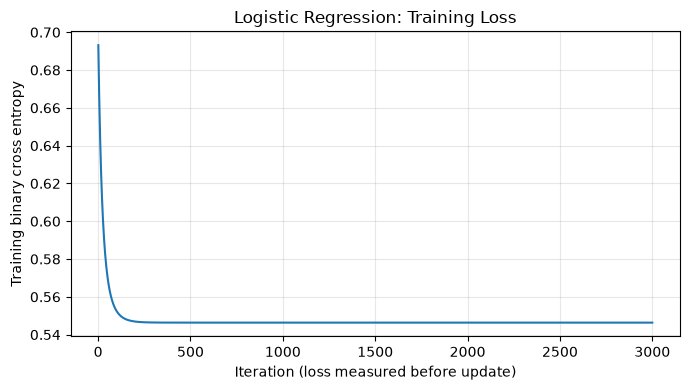

In [24]:
# 可视化辅助代码，不是模型实现。完成训练后再运行。
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(loss_history) + 1), loss_history)
ax.set_xlabel("Iteration (loss measured before update)")
ax.set_ylabel("Training binary cross entropy")
ax.set_title("Logistic Regression: Training Loss")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 16. 完成检查与学习记录

- [x] 数据固定为 2,000 条，训练 / 测试严格为 1,600 / 400，特征与标签对应。
- [x] 11 个函数全部实现，练习 A–I 的自检通过。
- [x] 标准化统计量只来自训练集，测试集和未来新样本复用同一组统计量。
- [x] 前向传播返回 `(m, 1)` 概率，BCE 返回平均损失标量。
- [x] `dW` 与 `W` 同形，`db` 为标量，更新方向正确。
- [x] 每轮记录更新前的训练损失，训练循环中没有测试数据。
- [x] 最后使用 0.5 阈值报告训练 / 测试 Accuracy，并报告训练 / 测试 BCE。
- [x] 不使用模拟生成器的系数、`z` 或 `prob` 训练，也不调用现成分类器。
- [x] 重启 kernel 后从头运行，确认结果不依赖隐藏状态。

### 运行记录 — 从头执行结果

2026-10-30：本目录环境，Python 3.13.5 / NumPy 2.5.4；新建 Jupyter kernel 后依次执行全部 24 个代码单元格，自检通过并生成训练曲线。
下表对应固定随机种子 42 的本次运行；修改配置后请重新执行并更新。

| 项目 | 你的结果 |
| --- | --- |
| 学习率 | 0.1 |
| 迭代次数 | 3,000 |
| 初始训练 BCE | 0.693147 |
| 最终训练 BCE | 0.546361 |
| 最终测试 BCE | 0.533845 |
| Train Accuracy | 72.5625% |
| Test Accuracy | 71.75% |
| 测试集多数类基线 Accuracy | 55.25% |

### 思考题 — 请写自己的解释

1. 为什么不能把 `prob` 直接作为训练答案，也不能直接复制模拟系数作为初始权重？
2. 为什么概率标签使模型即使正确学习到规律，也通常无法获得 100% 测试准确率？
3. `(m, 1)` 与 `(m,)` 相减为什么可能悄悄产生错误形状？
4. 为什么先在全部数据上求标准化统计量会泄漏测试集信息？
5. 学习率过大和过小，分别可能在训练曲线上出现什么现象？
6. 标准化后学到的权重处于新的特征尺度，为什么不能直接与模拟公式里的系数逐项比较？
7. 一个输入样本的三个特征增加时，模型学到的影响方向如何从权重中解释？
   这种解释是否足以证明现实世界中的因果关系？

### 排错速查

| 现象 | 优先检查 |
| --- | --- |
| `NotImplementedError` | 对应练习尚未补完，或修改后还没重新运行函数定义单元格 |
| 矩阵乘法维度错误 | `X` 是 `(m, d)`，`W` 是 `(d, 1)`，权重梯度是否正确转置 |
| 误差矩阵变成 `(m, m)` | 标签或概率被压成了一维，触发了广播 |
| 损失出现 NaN / Inf | `log(0)`、指数溢出、零标准差、学习率过大 |
| 损失持续上升 | 梯度符号、更新方向、是否重复或遗漏平均、学习率 |
| 每轮损失完全一样 | 参数是否真正更新，是否每轮重新初始化或忽略返回的新参数 |
| 自检通过但训练异常 | 检查是否读取全局 d、测试维度是否恰好掩盖错误；重启 kernel 后从头运行 |
| 训练表现很好但测试较差 | 先排查数据泄漏、预处理不一致，再考虑泛化与样本随机性 |

可选扩展（不属于本次核心要求）：数值稳定的 Sigmoid、用有限差分检查梯度、
从训练集划出验证集比较学习率、观察固定分类阈值改变后的结果。